# Chapter 19. Reinforcement Learning

Reinforcement learning involves a software _agent_ making observations on it's _environment_ and taking _actions_, recieving _rewards_ from the environment. These rewards can be positive or negative, the goal being to maximize the positive rewards over time.

### Policy Gradients

The algorithm a software agent uses is known as the _policy_ and there are a variety of techniques for optimizing this from random generation brute-force to genetic algorithms that use natural selection to cull bad policies and promote better ones, and finally optimization techniques that calculate the gradients of the rewards with regard to teh policy parameters known as _policy gradient_ (PG) algorithms.

#### Intro to the Gymnasium Library

In order to perform RL we need environments to train our agents! These _can_ be real environments but that gets very expensive and does not scale for most applications, so simulators are necessary. The Open source Gymnasium library (formerly OpenAI Gym) is available for emulating games, 2D and 3D physics simulations, etc.

In [10]:
import gymnasium as gym

env = gym.make("CartPole-v1", render_mode="rgb_array", max_episode_steps=1000)

In [11]:
obs, info = env.reset(seed=42)
obs

array([ 0.0273956 , -0.00611216,  0.03585979,  0.0197368 ], dtype=float32)

In [12]:
info

{}

In [13]:
gym.pprint_registry()

===== classic_control =====
Acrobot-v1             CartPole-v0            CartPole-v1
MountainCar-v0         MountainCarContinuous-v0 Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0     phys2d/CartPole-v1     phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3       BipedalWalkerHardcore-v3 CarRacing-v3
LunarLander-v3         LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1           CliffWalking-v1        CliffWalkingSlippery-v1
FrozenLake-v1          FrozenLake8x8-v1       Taxi-v4
===== tabular =====
tabular/Blackjack-v0   tabular/CliffWalking-v0
===== None =====
Ant-v2                 Ant-v3                 GymV21Environment-v0
GymV26Environment-v0   HalfCheetah-v2         HalfCheetah-v3
Hopper-v2              Hopper-v3              Humanoid-v2
Humanoid-v3            HumanoidStandup-v2     InvertedDoublePendulum-v2
InvertedPendulum-v2    Pusher-v2              Reacher-v2
Swimmer-v2             Swimmer-v3             Walker2d-v2
Walker2d-v3
===== mujoco =====
Ant-v4    

In [ ]:
img = env.render()
img.shape  # type: ignore

(400, 600, 3)

In [15]:
env.action_space

Discrete(2)

In [ ]:
action = 1  # accelerate right
obs, reward, done, truncated, info = env.step(action)
print(obs)
reward, done, truncated, info

[ 0.03104291  0.38306385  0.03102613 -0.5424507 ]


(1.0, False, False, {})

In [18]:
def basic_policy(obs):
    """accelerates left if pole leaning right, right if leaning left"""
    angle = obs[2]
    return 0 if angle < 0 else 1


totals = []
for episode in range(500):
    total_rewards = 0
    obs, info = env.reset(seed=episode)
    while True:
        action = basic_policy(obs)
        obs, reward, done, truncated, info = env.step(action)
        total_rewards += reward  # type: ignore
        if done or truncated:
            break
    totals.append(total_rewards)

41.698 8.389445512070509 24.0 63.0


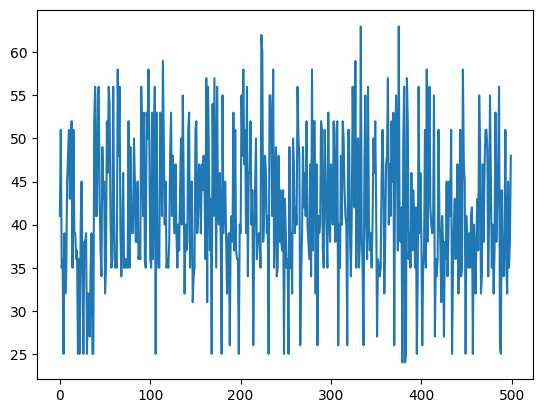

In [20]:
import matplotlib.pyplot as plt
import numpy as np

print(np.mean(totals), np.std(totals), min(totals), max(totals))

plt.plot(totals)
plt.show()